# Session 4 · What is a model, how good is it, and how do we keep it?
Chapters **03 Training** and **04 Testing**. Datasets: **Auto MPG** (regression, from Session 3) and **Breast Cancer** (classification).

- Part A: What *is* a model after `fit()`?
- Part B: How good is it? Metrics, cross-validation, overfitting.
- Part C: Save it, load it, use it somewhere else (the Stock App does exactly this).

In [1]:
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

pd.set_option("display.precision", 3)
print("scikit-learn", sklearn.__version__)

scikit-learn 1.8.0


In [2]:
from sklearn.model_selection import train_test_split

URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/mpg.csv"
df = pd.read_csv(URL).drop(columns=["name"])

X = df.drop(columns=["mpg"])
y = df["mpg"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(len(X_train), "train /", len(X_test), "test")

318 train / 80 test


## Part A · What is a model?
A model is a **function with numbers inside**: $\hat{y} = f(x)$. `fit()` finds the numbers, `predict()` uses them.
### 1 · The smallest model: one feature, two numbers

In [3]:
from sklearn.linear_model import LinearRegression

lin = LinearRegression().fit(X_train[["weight"]], y_train)
w, b = lin.coef_[0], lin.intercept_
print(f"w = {w:.5f} mpg per lb")
print(f"b = {b:.2f} mpg")

w = -0.00781 mpg per lb
b = 46.78 mpg


In [4]:
# The model IS these two numbers. Predict a 3000 lb car by hand, then with sklearn:
x = 3000
print(f"by hand : {w:.5f} * {x} + {b:.2f} = {w * x + b:.2f} mpg")
print(f"sklearn : {lin.predict(pd.DataFrame({'weight': [x]}))[0]:.2f} mpg")

by hand : -0.00781 * 3000 + 46.78 = 23.37 mpg
sklearn : 23.37 mpg


### 2 · More features, more numbers

In [5]:
num = ["cylinders", "displacement", "horsepower", "weight", "acceleration", "model_year"]
lin_all = LinearRegression().fit(X_train[num].fillna(X_train[num].median()), y_train)

pd.Series(lin_all.coef_, index=num).round(4)     # one weight per feature (+ one intercept)

cylinders       0.069
displacement    0.002
horsepower      0.003
weight         -0.007
acceleration    0.081
model_year      0.801
dtype: float64

Still a formula: $\hat{y} = w_1 x_1 + w_2 x_2 + \dots + w_6 x_6 + b$. Seven numbers. Careful: the weights are not comparable: `weight` is in pounds, `model_year` in years.
### 3 · A tree is a different kind of model: questions, not weights

In [6]:
from sklearn.tree import DecisionTreeRegressor, export_text

tree = DecisionTreeRegressor(max_depth=2, random_state=0).fit(X_train[num].fillna(X_train[num].median()), y_train)
print(export_text(tree, feature_names=num))

|--- displacement <= 190.50
|   |--- horsepower <= 76.50
|   |   |--- value: [32.77]
|   |--- horsepower >  76.50
|   |   |--- value: [25.70]
|--- displacement >  190.50
|   |--- horsepower <= 127.00
|   |   |--- value: [19.36]
|   |--- horsepower >  127.00
|   |   |--- value: [14.52]



`fit()` here does **not** use gradient descent. It searches for the question (feature + threshold) that splits the training cars into the most similar groups. The "numbers inside" are thresholds and leaf values.

In [7]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=300, random_state=42).fit(X_train[num].fillna(X_train[num].median()), y_train)
nodes = sum(t.tree_.node_count for t in rf.estimators_)
print(f"linear regression : {lin_all.coef_.size + 1} numbers")
print(f"random forest     : {len(rf.estimators_)} trees, {nodes:,} nodes")

linear regression : 7 numbers
random forest     : 300 trees, 100,840 nodes


### 4 · Parameters vs. hyperparameters
| | who sets it? | examples |
|---|---|---|
| **Parameter** | learned by `fit()` | weights $w$, bias $b$, tree thresholds |
| **Hyperparameter** | chosen by **us**, before `fit()` | `max_depth`, `n_estimators`, learning rate |

Choosing hyperparameters is part of **testing** (Part B).
### 5 · The preprocessing is part of the model
The scaler also *learns* numbers in `fit()`: the mean and standard deviation of every column in the **training** data.

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

def make_pipeline(model):
    numeric = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
    prep = ColumnTransformer([("num", numeric, num),
                              ("cat", OneHotEncoder(handle_unknown="ignore"), ["origin"])])
    return Pipeline([("prep", prep), ("model", model)])

pipe = make_pipeline(LinearRegression()).fit(X_train, y_train)
scaler = pipe.named_steps["prep"].named_transformers_["num"].named_steps["scale"]
pd.DataFrame({"mean": scaler.mean_, "std": scaler.scale_}, index=num)   # learned in fit(), too

,mean,std
cylinders,5.431,1.682
displacement,191.904,102.822
horsepower,103.107,37.034
weight,2969.016,839.295
acceleration,15.640,2.759
model_year,76.104,3.598


In [9]:
# What happens if we keep only the regression and forget the preprocessing?
car = X_test.iloc[[0]]
only_model = pipe.named_steps["model"]
print("true mpg               :", y_test.iloc[0])
print("pipeline               :", pipe.predict(car)[0].round(1))
origin = pipe.named_steps["prep"].named_transformers_["cat"].transform(car[["origin"]]).toarray()   # one-hot, as in training
print("model without scaling  :", only_model.predict(np.c_[car[num].to_numpy(), origin])[0].round(1))

true mpg               : 33.0
pipeline               : 32.5
model without scaling  : -10202.7


Without the scaler the regression receives `weight = 1795` where it learned "weight in standard deviations, about −2 … +3": a prediction of minus ten thousand mpg. **What we save and deploy is the whole pipeline**, never the model step alone.

## Part B · How good is the model?
### 6 · Regression metrics, by hand first
Three cars (illustrative numbers): true $y = [20, 30, 25]$, predicted $\hat{y} = [22, 27, 25]$.

| | car 1 | car 2 | car 3 | |
|---|---|---|---|---|
| error $e = y - \hat{y}$ | −2 | 3 | 0 | |
| $\lvert e \rvert$ | 2 | 3 | 0 | **MAE** = 5 / 3 = **1.67** |
| $e^2$ | 4 | 9 | 0 | MSE = 13 / 3 = 4.33 → **RMSE** = √4.33 = **2.08** |
| $(y - \bar{y})^2$, $\bar{y} = 25$ | 25 | 25 | 0 | **R²** = 1 − 13 / 50 = **0.74** |

- **MAE**: average miss, in mpg. Easy to explain.
- **RMSE**: also in mpg, but squares first, so big misses count more (2.08 > 1.67).
- **R²**: share of the variation the model explains. 0 = no better than always predicting the mean, 1 = perfect.

In [10]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

y_true, y_pred = np.array([20, 30, 25]), np.array([22, 27, 25])
print(f"MAE  {mean_absolute_error(y_true, y_pred):.2f}")
print(f"RMSE {root_mean_squared_error(y_true, y_pred):.2f}")
print(f"R2   {r2_score(y_true, y_pred):.2f}")

MAE  1.67
RMSE 2.08
R2   0.74


In [11]:
from sklearn.dummy import DummyRegressor

def scores(model):
    pred = make_pipeline(model).fit(X_train, y_train).predict(X_test)
    return {"MAE": mean_absolute_error(y_test, pred),
            "RMSE": root_mean_squared_error(y_test, pred),
            "R2": r2_score(y_test, pred)}

pd.DataFrame({
    "baseline (mean)": scores(DummyRegressor()),
    "linear regression": scores(LinearRegression()),
    "random forest": scores(RandomForestRegressor(n_estimators=300, random_state=42)),
}).T

,MAE,RMSE,R2
baseline (mean),5.955,7.347,-0.004
linear regression,2.288,2.888,0.845
random forest,1.599,2.179,0.912


**What does MAE ≈ 2 mpg mean?** The average car does 23.5 mpg; the random forest misses by 1.6 mpg on average, about 7 %. The baseline misses by 6 mpg. Whether that is "good" depends on the use case (chapter 01), not on the metric.

Text(0.5, 1.0, 'Points on the diagonal = perfect predictions')

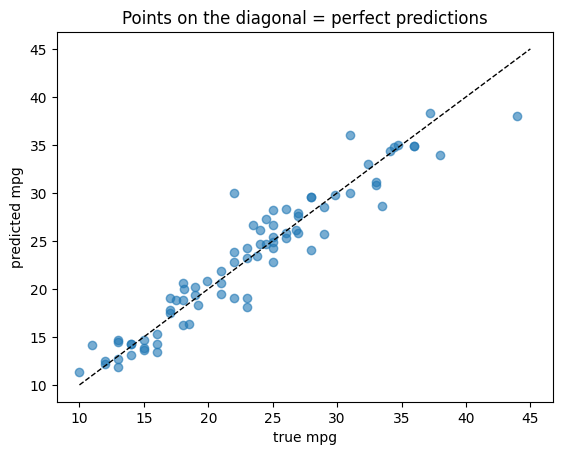

In [12]:
pred = make_pipeline(RandomForestRegressor(n_estimators=300, random_state=42)).fit(X_train, y_train).predict(X_test)
plt.scatter(y_test, pred, alpha=0.6)
plt.plot([10, 45], [10, 45], "k--", lw=1)
plt.xlabel("true mpg"); plt.ylabel("predicted mpg")
plt.title("Points on the diagonal = perfect predictions")

### 7 · Is one test split enough?
80 test cars is not much. Which cars land in the test set is luck. Let's change only the random seed of the split:

MAE over 20 different splits: min 2.10, max 2.91


Text(0, 0.5, 'test MAE')

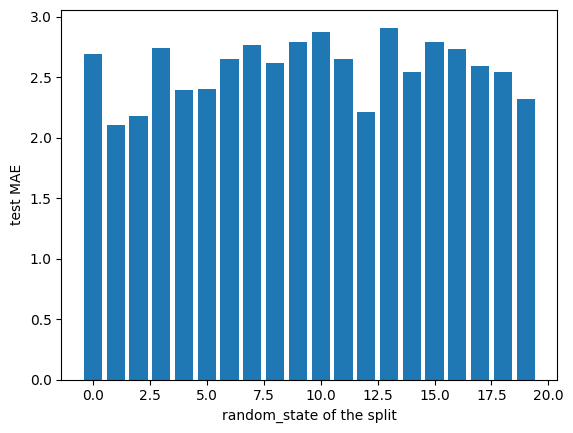

In [13]:
maes = []
for seed in range(20):
    Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.2, random_state=seed)
    model = make_pipeline(LinearRegression()).fit(Xa, ya)
    maes.append(mean_absolute_error(yb, model.predict(Xb)))

print(f"MAE over 20 different splits: min {min(maes):.2f}, max {max(maes):.2f}")
plt.bar(range(20), maes); plt.xlabel("random_state of the split"); plt.ylabel("test MAE")

Same model, same data, only a different split: the MAE moves noticeably. A single number can make a model look better or worse than it is.
### 8 · Cross-validation: every car is tested once
**5-fold CV:** cut the training data into 5 parts. Train on 4, test on the 5th. Repeat 5 times, so every part is the test part once. Result: 5 scores → mean ± standard deviation.

```
fold 1:  [TEST] train  train  train  train
fold 2:  train [TEST]  train  train  train
...
fold 5:  train  train  train  train [TEST]
```

In [14]:
from sklearn.model_selection import cross_val_score

for name, model in [("linear regression", LinearRegression()),
                    ("random forest", RandomForestRegressor(n_estimators=300, random_state=42))]:
    cv = -cross_val_score(make_pipeline(model), X_train, y_train, cv=5, scoring="neg_mean_absolute_error")
    print(f"{name:18s} MAE per fold {cv.round(2)}  ->  {cv.mean():.2f} ± {cv.std():.2f}")

linear regression  MAE per fold [2.6  2.41 2.69 2.77 2.87]  ->  2.67 ± 0.16


random forest      MAE per fold [1.99 1.99 2.3  2.46 2.06]  ->  2.16 ± 0.19


Look at the random forest: test MAE 1.60 (section 6), but cross-validation says 2.16. Our test split was a **lucky** one. The CV number is the more honest estimate.

`scoring` in sklearn means "higher is better", so errors come back negative: `neg_mean_absolute_error`. The minus sign in front turns them back into MAE.

Rule: **choose the model with cross-validation on the training data. Touch the test set once, at the end.**
### 9 · Overfitting, measured
A tree with `max_depth=None` can memorise every training car. Train error and CV error tell the story:

Text(0.5, 1.0, 'Train error falls to 0, CV error stays: the gap is overfitting')

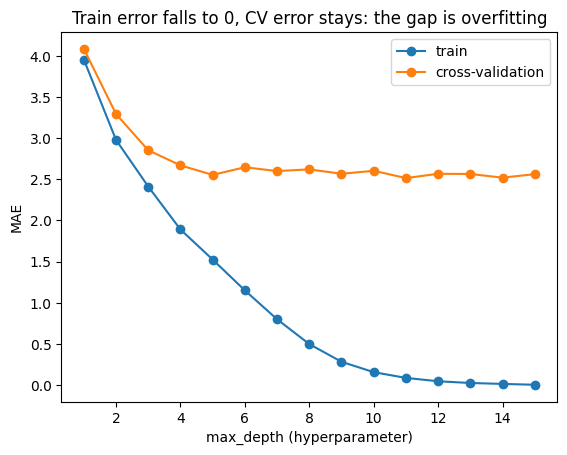

In [15]:
from sklearn.model_selection import validation_curve

depths = range(1, 16)
train_s, cv_s = validation_curve(make_pipeline(DecisionTreeRegressor(random_state=0)), X_train, y_train,
                                 param_name="model__max_depth", param_range=depths,
                                 cv=5, scoring="neg_mean_absolute_error")
plt.plot(depths, -train_s.mean(axis=1), "o-", label="train")
plt.plot(depths, -cv_s.mean(axis=1), "o-", label="cross-validation")
plt.xlabel("max_depth (hyperparameter)"); plt.ylabel("MAE"); plt.legend()
plt.title("Train error falls to 0, CV error stays: the gap is overfitting")

- Left (depth 1–2): both errors high → **underfitting**, the model is too simple.
- Right: train error → 0, CV error stays at about 2.5. The growing **gap** is overfitting: every extra level only memorises training cars, it doesn't help on new ones. (On other data the CV error even rises again.)
- Choose the simplest model where the CV curve is (nearly) lowest: here about `max_depth=5`. This is how we choose hyperparameters.

### 10 · Classification: when accuracy is not enough
Breast Cancer dataset: 569 tumours, 30 measurements each. Is the tumour **malignant**?

In [16]:
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer(as_frame=True)
Xc = data.data
yc = (data.target == 0).astype(int)        # sklearn codes 0 = malignant. We want 1 = malignant (the case we look for)
print(yc.value_counts().rename({0: "benign", 1: "malignant"}))

Xc_train, Xc_test, yc_train, yc_test = train_test_split(Xc, yc, test_size=0.25, stratify=yc, random_state=42)

target
benign       357
malignant    212
Name: count, dtype: int64


Four outcomes. Small example (illustrative): 10 patients, 4 really malignant.

| | predicted malignant | predicted benign |
|---|---|---|
| **really malignant** | TP = 3 | FN = 1 (missed!) |
| **really benign** | FP = 2 (false alarm) | TN = 4 |

- **Accuracy** = (TP + TN) / all = 7 / 10 = **0.70**
- **Precision** = TP / (TP + FP) = 3 / 5 = **0.60**: when the model says "malignant", how often is it right?
- **Recall** = TP / (TP + FN) = 3 / 4 = **0.75**: of all malignant tumours, how many did we find?

In [17]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, ConfusionMatrixDisplay

clf = Pipeline([("scale", StandardScaler()), ("model", LogisticRegression(max_iter=1000))]).fit(Xc_train, yc_train)
base = DummyClassifier(strategy="most_frequent").fit(Xc_train, yc_train)

for name, m in [("baseline: always 'benign'", base), ("logistic regression", clf)]:
    p = m.predict(Xc_test)
    print(f"{name:26s} accuracy {accuracy_score(yc_test, p):.3f}  "
          f"precision {precision_score(yc_test, p, zero_division=0):.3f}  recall {recall_score(yc_test, p):.3f}")

baseline: always 'benign'  accuracy 0.629  precision 0.000  recall 0.000
logistic regression        accuracy 0.965  precision 0.980  recall 0.925


The baseline reaches over 60 % accuracy and finds **zero** malignant tumours (recall 0). Accuracy alone hides that.

Text(0.5, 1.0, 'Rows: truth, columns: prediction')

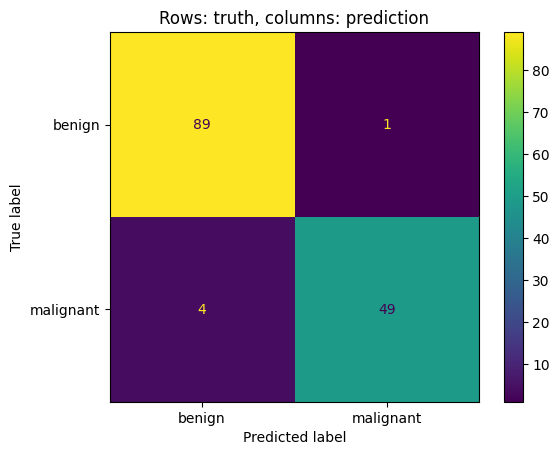

In [18]:
ConfusionMatrixDisplay.from_estimator(clf, Xc_test, yc_test, display_labels=["benign", "malignant"])
plt.title("Rows: truth, columns: prediction")

In [19]:
# The model outputs a probability. predict() uses the threshold 0.5. We can choose a different one:
proba = clf.predict_proba(Xc_test)[:, 1]
for t in [0.5, 0.3, 0.1]:
    p = (proba >= t).astype(int)
    print(f"threshold {t}:  precision {precision_score(yc_test, p):.3f}  recall {recall_score(yc_test, p):.3f}  "
          f"missed tumours {((p == 0) & (yc_test == 1)).sum()}")

threshold 0.5:  precision 0.980  recall 0.925  missed tumours 4
threshold 0.3:  precision 0.981  recall 0.962  missed tumours 2
threshold 0.1:  precision 0.897  recall 0.981  missed tumours 1


Lower threshold → more alarms → fewer missed tumours, more false alarms. Which mistake is worse is a **use-case decision** (chapter 01). For a cancer screening: a missed tumour.

## Part C · Save, load, use
### 11 · Train the final model and save it
We chose the random forest with cross-validation. Now: train it, test it once, save it.

In [20]:
import joblib

final = make_pipeline(RandomForestRegressor(n_estimators=300, random_state=42)).fit(X_train, y_train)
test_mae = mean_absolute_error(y_test, final.predict(X_test))

MODELS = Path("models")
MODELS.mkdir(exist_ok=True)
joblib.dump(final, MODELS / "mpg_model.joblib")
print(f"test MAE {test_mae:.2f} mpg, file size {(MODELS / 'mpg_model.joblib').stat().st_size / 1e6:.1f} MB")

test MAE 1.60 mpg, file size 7.3 MB


In [21]:
# For comparison: the linear pipeline
joblib.dump(pipe, MODELS / "mpg_linear.joblib")
print(f"{(MODELS / 'mpg_linear.joblib').stat().st_size / 1e3:.1f} KB")

3.7 KB


Megabytes vs. kilobytes: the forest stores tens of thousands of nodes, the linear model a few numbers. Size matters on a small server or a microcontroller.
### 12 · A model file alone is not enough: metadata
In three months nobody knows which features, which data, which sklearn version, which score. So we write it down next to the model:

In [22]:
meta = {
    "model_file": "mpg_model.joblib",
    "trained_at": time.strftime("%Y-%m-%d %H:%M"),
    "sklearn_version": sklearn.__version__,
    "features": list(X_train.columns),
    "target": "mpg",
    "train_rows": len(X_train),
    "test_mae": round(test_mae, 3),
}
(MODELS / "mpg_model.json").write_text(json.dumps(meta, indent=2))
print(json.dumps(meta, indent=2))

{
  "model_file": "mpg_model.joblib",
  "trained_at": "2026-11-01 16:49",
  "sklearn_version": "1.8.0",
  "features": [
    "cylinders",
    "displacement",
    "horsepower",
    "weight",
    "acceleration",
    "model_year",
    "origin"
  ],
  "target": "mpg",
  "train_rows": 318,
  "test_mae": 1.599
}


### 13 · Load it, as if we were a different program

In [23]:
loaded = joblib.load(MODELS / "mpg_model.joblib")
meta = json.loads((MODELS / "mpg_model.json").read_text())

new_car = pd.DataFrame([{"cylinders": 4, "displacement": 120, "horsepower": 90, "weight": 2400,
                         "acceleration": 16, "model_year": 80, "origin": "japan"}])
print(f"predicted: {loaded.predict(new_car)[0]:.1f} mpg (expected error about ±{meta['test_mae']:.1f} mpg)")

predicted: 33.9 mpg (expected error about ±1.6 mpg)


In [24]:
# Same model -> exactly the same predictions as before saving
print("identical:", np.array_equal(final.predict(X_test), loaded.predict(X_test)))

identical: True


In [25]:
# The pipeline checks its input: a missing column is an error, not a silent wrong prediction
try:
    loaded.predict(new_car.drop(columns=["horsepower"]))
except ValueError as e:
    print("ValueError:", str(e)[:120])

ValueError: columns are missing: {'horsepower'}


### 14 · Two warnings
- **joblib/pickle files can contain code.** Loading a file runs that code. Only load models you created yourself or got from a trusted source. (Alternatives for sharing: `skops`, ONNX.)
- **Versions must match.** A model saved with scikit-learn 1.8 may fail or warn under another version. That's why `sklearn_version` is in the metadata, and why projects pin versions in `requirements.txt`.

### 15 · Back to the Stock App
```
train.py  : load data -> features -> pipeline.fit() -> CV + test -> joblib.dump()   (runs rarely)
app.py    : joblib.load() once at start -> pipeline.predict() for every user request (Streamlit)
```
Training is slow and happens once; prediction is fast and happens all the time. The `.joblib` file is the interface between the two. Chapter 05 (Deployment) puts `app.py` on a server.

**Summary**
| Question | Answer |
|---|---|
| What is a model? | A function with learned numbers: weights, or tree thresholds. Preprocessing included. |
| How good is it? | Metric that fits the use case (MAE, recall …), compared to a baseline, measured with cross-validation. Test set once, at the end. |
| How do we keep it? | `joblib.dump(pipeline)` + metadata (features, version, score). Load only trusted files. |